In [3]:
## Compre ESCO_coverage_by-programme with demand_by_programme

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "data/processed").exists():
    ROOT = ROOT.parent

DATA = ROOT / "data" / "processed"

esco_coverage = pd.read_csv(DATA / "ESCO_coverage_by_programme.csv")
demand = pd.read_csv(DATA / "demand_by_programme.csv")


### ESCO profile skills mentioned in job postings

For each programme, this chart shows how many skills from its selected ESCO occupation profile were found in the job-posting texts, and what share of the profile that represents. The labels show the number mentioned, the total profile skills, and the percentage. This measures overlap with the ESCO baseline — not the share of postings requesting those skills.

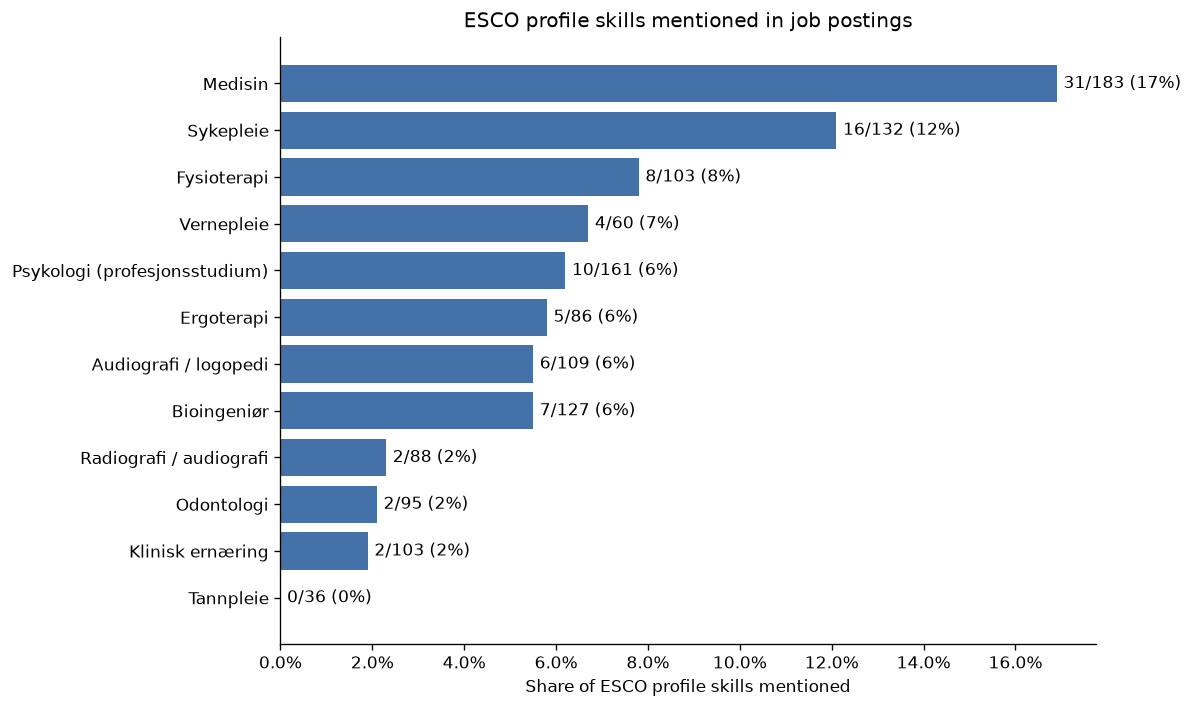

In [10]:
from matplotlib.ticker import PercentFormatter

plot_data = esco_coverage.sort_values("share_profile_mentioned")

labels = [
    f"{int(mentioned)}/{int(total)} ({share:.0%})"
    for mentioned, total, share in zip(
        plot_data["profile_skills_mentioned"],
        plot_data["profile_skills"],
        plot_data["share_profile_mentioned"],
    )
]

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(
    plot_data["programme"],
    plot_data["share_profile_mentioned"],
    color="#4472A8",
)

ax.bar_label(bars, labels=labels, padding=4)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set_title("ESCO profile skills mentioned in job postings")
ax.set_xlabel("Share of ESCO profile skills mentioned")
ax.set_ylabel("")

fig.tight_layout()
plt.show()